<a href="https://colab.research.google.com/github/Valeria1100/Confiabilidad-y-planeaci-n-de-capacidad-de-un-servicio-de-inferencia-de-IA./blob/main/EjerciciosD_y_E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Fonseca Puntos D Y E

# Parte D — Dependencias y esperanza condicional

In [178]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, norm

In [179]:
# Definimos la semilla del grupo
S = 4063981172

# Calculamos los límites de las clases de tamaño
t1 = 80 + 10 * (S % 5)
t2 = 400 + 25 * (S % 5)

# Nivel de confianza
confianza = 0.99
alpha = 1 - confianza

# Generador aleatorio del proyecto
rng = np.random.default_rng(S)

# Mostramos los parámetros
print("Semilla:", S)
print("t1:", t1, "KB")
print("t2:", t2, "KB")
print("Nivel de confianza:", confianza)

Semilla: 4063981172
t1: 100 KB
t2: 450 KB
Nivel de confianza: 0.99


**D1.** Con las clases de tamaño definidas por t1, t2, construya la distribución conjunta
empírica de (clase de tamaño, cache_hit). Obtenga marginales y condicionales, y determine –con
evidencia cuantitativa e intervalos– si las dos variables son independientes. Figura 4 (mapa de
calor).

In [180]:
# Cargamos los datos de solicitudes
solicitudes = pd.read_csv("solicitudes.csv")

# Creamos una copia para trabajar con los datos
datos_d1 = solicitudes.copy()

# Definimos las condiciones para clasificar el tamaño
condiciones = [
    datos_d1["tam_kb"] < t1,
    (datos_d1["tam_kb"] >= t1) & (datos_d1["tam_kb"] < t2),
    datos_d1["tam_kb"] >= t2
]

# Definimos los nombres de las clases
clases = ["Pequeña", "Mediana", "Grande"]

# Asignamos una clase a cada solicitud
datos_d1["clase_tamano"] = pd.Categorical(
    np.select(condiciones, clases, default="Sin clasificar"),
    categories=clases,
    ordered=True
)

# Mostramos las primeras filas
print("Primeras solicitudes clasificadas:")
print(datos_d1[["tam_kb", "clase_tamano", "cache_hit"]].head())

# Revisamos la cantidad de solicitudes por clase
print("\nCantidad de solicitudes por clase:")
print(datos_d1["clase_tamano"].value_counts().sort_index())

# Verificamos que ninguna solicitud haya quedado sin clasificar
print("\nSolicitudes sin clasificar:")
print(datos_d1["clase_tamano"].isna().sum())

Primeras solicitudes clasificadas:
   tam_kb clase_tamano  cache_hit
0  108.47      Mediana          0
1  629.91       Grande          0
2  179.72      Mediana          0
3  429.34      Mediana          0
4  229.65      Mediana          0

Cantidad de solicitudes por clase:
clase_tamano
Pequeña     6496
Mediana    22332
Grande      3644
Name: count, dtype: int64

Solicitudes sin clasificar:
0


In [181]:
# Construimos la tabla de frecuencias conjuntas
tabla_conjunta = pd.crosstab(
    datos_d1["clase_tamano"],
    datos_d1["cache_hit"]
)

# Organizamos las filas y columnas
tabla_conjunta = tabla_conjunta.reindex(
    index=clases,
    columns=[0, 1],
    fill_value=0
)

# Mostramos la frecuencia conjunta
print("Distribución conjunta (frecuencias):")
print(tabla_conjunta)

# Calculamos la distribución conjunta en probabilidades
distribucion_conjunta = tabla_conjunta / len(datos_d1)

print("\nDistribución conjunta (probabilidades):")
print(distribucion_conjunta)

# Calculamos las distribuciones marginales
marginal_tamano = distribucion_conjunta.sum(axis=1)
marginal_cache = distribucion_conjunta.sum(axis=0)

print("\nMarginal de clase de tamaño:")
print(marginal_tamano)
print("\nMarginal de cache_hit:")
print(marginal_cache)

Distribución conjunta (frecuencias):
cache_hit         0     1
clase_tamano             
Pequeña        3045  3451
Mediana       15086  7246
Grande         2975   669

Distribución conjunta (probabilidades):
cache_hit            0         1
clase_tamano                    
Pequeña       0.093773  0.106276
Mediana       0.464585  0.223146
Grande        0.091617  0.020602

Marginal de clase de tamaño:
clase_tamano
Pequeña    0.200049
Mediana    0.687731
Grande     0.112220
dtype: float64

Marginal de cache_hit:
cache_hit
0    0.649975
1    0.350025
dtype: float64


In [182]:
# Calculamos P(cache_hit | clase de tamaño)
condicional_cache = tabla_conjunta.div(tabla_conjunta.sum(axis=1),axis=0)
print("Probabilidad de cache_hit según el tamaño:")
print(condicional_cache)

# Calculamos P(clase de tamaño | cache_hit)
condicional_tamano = tabla_conjunta.div(tabla_conjunta.sum(axis=0),axis=1)
print("\nProbabilidad de clase de tamaño según cache_hit:")
print(condicional_tamano)

Probabilidad de cache_hit según el tamaño:
cache_hit            0         1
clase_tamano                    
Pequeña       0.468750  0.531250
Mediana       0.675533  0.324467
Grande        0.816411  0.183589

Probabilidad de clase de tamaño según cache_hit:
cache_hit            0         1
clase_tamano                    
Pequeña       0.144272  0.303625
Mediana       0.714773  0.637515
Grande        0.140955  0.058860


In [183]:
# Calculamos los intervalos de confianza de Wilson
def intervalo_wilson(exitos, total):

    z = norm.ppf(1 - alpha / 2)
    p = exitos / total
    denominador = 1 + (z ** 2 / total)

    centro = (
        p + (z ** 2 / (2 * total))
    ) / denominador

    margen = z * np.sqrt(
        (p * (1 - p) / total) +
        (z ** 2 / (4 * total ** 2))
    ) / denominador

    inferior = centro - margen
    superior = centro + margen
    return p, inferior, superior

# Calculamos los intervalos de cache_hit para cada clase
print("Intervalos de confianza del 99%:")

for clase in clases:

    total = tabla_conjunta.loc[clase].sum()
    exitos = tabla_conjunta.loc[clase, 1]
    resultado = intervalo_wilson(exitos, total)

    print("\nClase:", clase)
    print("Probabilidad:", resultado[0])
    print("Límite inferior:", resultado[1])
    print("Límite superior:", resultado[2])

Intervalos de confianza del 99%:

Clase: Pequeña
Probabilidad: 0.53125
Límite inferior: 0.515277928734091
Límite superior: 0.5471583000340687

Clase: Mediana
Probabilidad: 0.3244671323661114
Límite inferior: 0.3164505150288441
Límite superior: 0.3325880212877635

Clase: Grande
Probabilidad: 0.18358946212952798
Límite inferior: 0.16764968161813507
Límite superior: 0.20067937200838995


In [184]:
# Aplicamos la prueba chi-cuadrado
chi2, p_valor, grados_libertad, esperados = chi2_contingency(
    tabla_conjunta,
    correction=False
)

# Calculamos el coeficiente V de Cramer
total = tabla_conjunta.to_numpy().sum()

v_cramer = np.sqrt(
    chi2 / (
        total * min(
            tabla_conjunta.shape[0] - 1,
            tabla_conjunta.shape[1] - 1
        )
    )
)

print("RESULTADOS DE INDEPENDENCIA")
print("Estadístico chi-cuadrado:", chi2)
print("Grados de libertad:", grados_libertad)
print("Valor p:", p_valor)
print("V de Cramer:", v_cramer)

# Comparamos el valor p con el nivel de significancia
if p_valor < alpha:
    print("\nSe rechaza la hipótesis de independencia.")
else:
    print("\nNo se rechaza la hipótesis de independencia.")

RESULTADOS DE INDEPENDENCIA
Estadístico chi-cuadrado: 1445.5526962734114
Grados de libertad: 2
Valor p: 0.0
V de Cramer: 0.21099027825973948

Se rechaza la hipótesis de independencia.


In [185]:
# Obtenemos las cantidades de cada clase
n_pequena = int(tabla_conjunta.loc["Pequeña"].sum())
n_grande = int(tabla_conjunta.loc["Grande"].sum())

# Obtenemos las proporciones observadas de cache_hit
p_pequena = (
    tabla_conjunta.loc["Pequeña", 1] / n_pequena
)

p_grande = (
    tabla_conjunta.loc["Grande", 1] / n_grande
)

# Calculamos la diferencia observada
diferencia = p_pequena - p_grande
repeticiones = 20000

simulacion_pequena = rng.binomial(
    n_pequena,
    p_pequena,
    size=repeticiones
) / n_pequena

simulacion_grande = rng.binomial(
    n_grande,
    p_grande,
    size=repeticiones
) / n_grande

# Calculamos las diferencias simuladas
diferencias = simulacion_pequena - simulacion_grande

# Obtenemos el intervalo del 99%
limite_inferior = np.quantile(diferencias, alpha / 2)
limite_superior = np.quantile(diferencias, 1 - alpha / 2)

print("Diferencia de probabilidades:", diferencia)
print("Intervalo de confianza del 99%:")
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Diferencia de probabilidades: 0.347660537870472
Intervalo de confianza del 99%:
Límite inferior: 0.32461577385458523
Límite superior: 0.37062486819550855


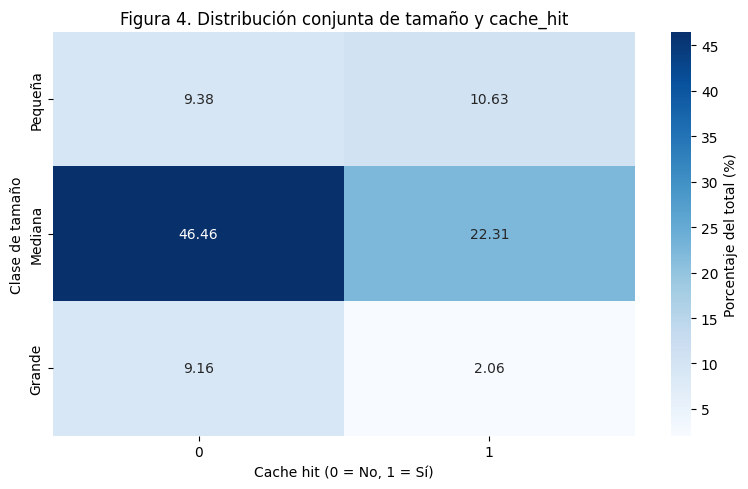

In [186]:
# Creamos el tamaño de la figura
plt.figure(figsize=(8, 5))
# Convertimos las probabilidades a porcentajes
datos_grafica = distribucion_conjunta * 100

# Construimos el mapa de calor
sns.heatmap(
    datos_grafica,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar_kws={"label": "Porcentaje del total (%)"}
)

# Colocamos el título y los nombres de los ejes
plt.title("Figura 4. Distribución conjunta de tamaño y cache_hit")
plt.xlabel("Cache hit (0 = No, 1 = Sí)")
plt.ylabel("Clase de tamaño")
plt.tight_layout()
plt.show()

**D2.** Estime E[G | clase, no caché] y E[G | tam_kb] de forma no paramétrica. Verifique
numéricamente la ley de la esperanza total y la de la varianza total para G, y cuantifique qué
fracción de Var(G) queda explicada por la clase de tamaño.


In [187]:
# Creamos una copia de los datos de D1
datos_d2 = datos_d1.copy()

# Revisamos los valores faltantes de gpu_ms
print("Valores faltantes de GPU:")
print(datos_d2["gpu_ms"].isna().sum())

# Revisamos los faltantes de solicitudes con caché
faltantes_cache = ((datos_d2["cache_hit"] == 1) &(datos_d2["gpu_ms"].isna())).sum()
# Completamos con cero porque no utilizaron GPU
datos_d2.loc[(datos_d2["cache_hit"] == 1) &(datos_d2["gpu_ms"].isna()),"gpu_ms"] = 0

print("Faltantes con caché:", faltantes_cache)

# Eliminamos los datos donde no conocemos el tiempo de GPU
datos_d2 = datos_d2.dropna(subset=["gpu_ms"])

print("\nCantidad de solicitudes disponibles:", len(datos_d2))

Valores faltantes de GPU:
32
Faltantes con caché: 14

Cantidad de solicitudes disponibles: 32454


In [188]:
# Separamos las solicitudes que no utilizaron caché
datos_no_cache = datos_d2[datos_d2["cache_hit"] == 0].copy()

# Mostramos la cantidad de solicitudes sin caché y Revisamos los tiempos de GPU
print("Solicitudes sin caché:", len(datos_no_cache))
print("\nPrimeros tiempos de GPU:")
print(datos_no_cache["gpu_ms"].head())

Solicitudes sin caché: 21088

Primeros tiempos de GPU:
0      8.37
1    149.39
2     49.68
3     66.91
4     33.09
Name: gpu_ms, dtype: float64


In [189]:
# Agrupamos las solicitudes según su clase de tamaño
esperanza_clase = datos_no_cache.groupby(
    "clase_tamano",
    observed=False
)["gpu_ms"].agg(
    ["count", "mean", "std"]
)

# Cambiamos los nombres de las columnas
esperanza_clase.columns = ["Cantidad","Promedio_GPU_ms","Desviacion_GPU_ms"]

# Mostramos los resultados
print("Esperanza del tiempo de GPU según la clase:")
display(esperanza_clase)

Esperanza del tiempo de GPU según la clase:


,Cantidad,Promedio_GPU_ms,Desviacion_GPU_ms
clase_tamano,,,
Pequeña,3043,22.102189,13.417924
Mediana,15074,46.034335,30.725862
Grande,2971,98.652874,62.568484


In [190]:
# Dividimos los tamaños en 20 grupos
datos_d2["grupo_tamano"] = pd.qcut(
    datos_d2["tam_kb"],
    q=20,
    duplicates="drop"
)

# Calculamos el promedio de GPU para cada grupo
tabla_tamano = datos_d2.groupby(
    "grupo_tamano",
    observed=True
).agg(
    cantidad=("gpu_ms", "count"),
    tamano_promedio=("tam_kb", "mean"),
    tiempo_promedio=("gpu_ms", "mean")
)

print("Esperanza de GPU según el tamaño:")
display(tabla_tamano)

Esperanza de GPU según el tamaño:


,cantidad,tamano_promedio,tiempo_promedio
grupo_tamano,,,
"(0.159, 43.7]",1624,27.990363,8.058060
"(43.7, 65.343]",1622,54.695937,9.678446
"(65.343, 83.018]",1622,74.380691,11.435561
"(83.018, 99.938]",1623,91.598792,12.234868
"(99.938, 116.16]",1624,108.103922,18.846509
"(116.16, 132.94]",1622,124.403471,20.951560
"(132.94, 148.55]",1624,140.872876,22.295690
"(148.55, 165.08]",1622,157.036628,23.373058
"(165.08, 182.788]",1621,174.026675,24.552943


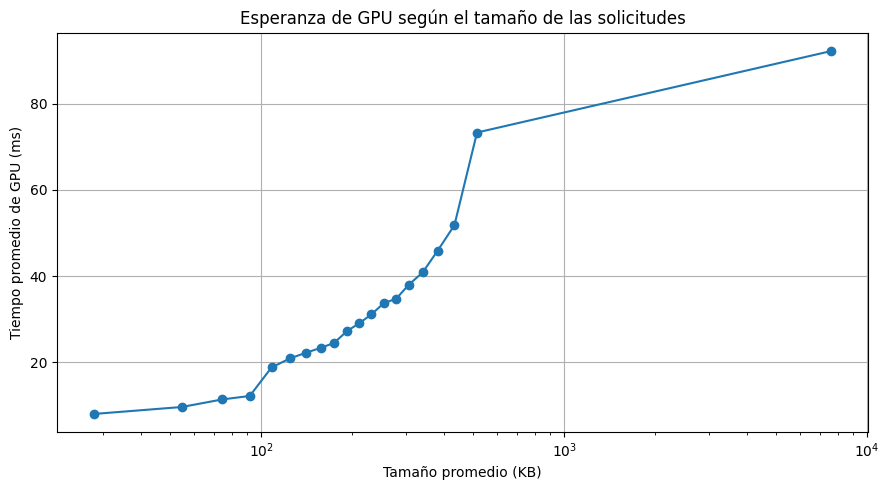

In [191]:
plt.figure(figsize=(9, 5))
plt.plot(tabla_tamano["tamano_promedio"],tabla_tamano["tiempo_promedio"],marker="o")
plt.title("Esperanza de GPU según el tamaño de las solicitudes")
plt.xlabel("Tamaño promedio (KB)")
plt.ylabel("Tiempo promedio de GPU (ms)")
plt.xscale("log")
plt.grid()
plt.tight_layout()
plt.show()

In [192]:
# Calculamos el promedio general de GPU
esperanza_general = datos_d2["gpu_ms"].mean()

# Agrupamos los datos según su clase
resumen_clases = datos_d2.groupby(
    "clase_tamano",
    observed=False
).agg(
    cantidad=("gpu_ms", "count"),
    promedio=("gpu_ms", "mean")
)

# Calculamos la probabilidad de cada clase
resumen_clases["probabilidad"] = (
    resumen_clases["cantidad"] / len(datos_d2)
)

# Calculamos la esperanza utilizando las clases
esperanza_por_clases = (
    resumen_clases["probabilidad"] *
    resumen_clases["promedio"]
).sum()

print("LEY DE LA ESPERANZA TOTAL")
print("Esperanza general:", esperanza_general)
print("Esperanza por clases:", esperanza_por_clases)
print("Diferencia:",abs(esperanza_general - esperanza_por_clases))

# Verificamos si ambos resultados coinciden
if np.isclose(esperanza_general, esperanza_por_clases):
    print("\nSe cumple la ley de la esperanza total.")
else:
    print("\nNo se cumple la ley de la esperanza total.")

LEY DE LA ESPERANZA TOTAL
Esperanza general: 32.4852471189992
Esperanza por clases: 32.485247118999204
Diferencia: 7.105427357601002e-15

Se cumple la ley de la esperanza total.


In [193]:
# Calculamos la varianza dentro de cada clase
varianza_clases = datos_d2.groupby(
    "clase_tamano",
    observed=False
)["gpu_ms"].var(ddof=0)

# Agregamos las varianzas a nuestra tabla anterior
resumen_clases["varianza"] = varianza_clases
# Calculamos la varianza total de GPU
varianza_general = datos_d2["gpu_ms"].var(ddof=0)

# Calculamos la varianza dentro de las clases
varianza_dentro = (
    resumen_clases["probabilidad"] *
    resumen_clases["varianza"]
).sum()

# Calculamos la varianza entre las clases
varianza_entre = (
    resumen_clases["probabilidad"] *
    (resumen_clases["promedio"] - esperanza_general) ** 2
).sum()

# Sumamos los dos componentes
varianza_calculada = varianza_dentro + varianza_entre


print("LEY DE LA VARIANZA TOTAL")
print("Varianza general:", varianza_general)
print("Varianza dentro de las clases:", varianza_dentro)
print("Varianza entre las clases:", varianza_entre)
print("Suma de las dos varianzas:", varianza_calculada)
print("Diferencia:",abs(varianza_general - varianza_calculada))

# Comprobamos la igualdad
if np.isclose(varianza_general, varianza_calculada):
    print("\nSe cumple la ley de la varianza total.")
else:
    print("\nNo se cumple la ley de la varianza total.")

LEY DE LA VARIANZA TOTAL
Varianza general: 1679.3625312861616
Varianza dentro de las clases: 1321.2384602405702
Varianza entre las clases: 358.1240710458117
Suma de las dos varianzas: 1679.362531286382
Diferencia: 2.2032509150449187e-10

Se cumple la ley de la varianza total.


In [194]:
# Calculamos la fracción de varianza explicada
fraccion_explicada = varianza_entre / varianza_general
# Convertimos el resultado a porcentaje
porcentaje_explicado = fraccion_explicada * 100

print("RESULTADO FINAL D2")
print("Fracción explicada:", fraccion_explicada)
print("Porcentaje explicado:", porcentaje_explicado, "%")

RESULTADO FINAL D2
Fracción explicada: 0.2132500066983975
Porcentaje explicado: 21.32500066983975 %


**D3.** Ajuste un modelo lineal para E[G | tam_kb, no caché] por mínimos cuadrados,
planteando y resolviendo usted mismo el sistema matricial correspondiente (sin sklearn ni
statsmodels). Entregue intervalos de confianza para los coeficientes, analice los residuos y, si
encuentra una violación de supuestos, proponga y aplique una corrección fundamentada en la
estructura probabilística de los datos. Figura 5.


In [195]:
# Creamos una copia de los datos
datos_d3 = datos_d2.copy()

# Seleccionamos las solicitudes que no utilizaron caché
datos_d3 = datos_d3[
    datos_d3["cache_hit"] == 0
].copy()

# Eliminamos los registros que no tienen tiempo de GPU
datos_d3 = datos_d3.dropna(
    subset=["tam_kb", "gpu_ms"]
)

print("Solicitudes para el modelo:", len(datos_d3))

# Revisamos las primeras filas
display(datos_d3[["tam_kb", "gpu_ms"]].head())

Solicitudes para el modelo: 21088


,tam_kb,gpu_ms
0,108.47,8.37
1,629.91,149.39
2,179.72,49.68
3,429.34,66.91
4,229.65,33.09


In [196]:
# Variable independiente: tamaño de las solicitudes
x = datos_d3["tam_kb"].to_numpy()
# Variable dependiente: tiempo de GPU
y = datos_d3["gpu_ms"].to_numpy()

# La primera columna corresponde al intercepto
X = np.column_stack((np.ones(len(x)),x))

print("Dimensiones de X:", X.shape)
print("Cantidad de tiempos de GPU:", len(y))
print("\nPrimeras filas de la matriz X:")
print(X[:5])
print("\nPrimeros valores de GPU:")
print(y[:5])

Dimensiones de X: (21088, 2)
Cantidad de tiempos de GPU: 21088

Primeras filas de la matriz X:
[[  1.   108.47]
 [  1.   629.91]
 [  1.   179.72]
 [  1.   429.34]
 [  1.   229.65]]

Primeros valores de GPU:
[  8.37 149.39  49.68  66.91  33.09]


In [197]:
# Calculamos la matriz X transpuesta por X
XtX = X.T @ X
# Calculamos la matriz X transpuesta por Y
XtY = X.T @ y

# Resolvemos el sistema matricial
# (X transpuesta por X) * beta = X transpuesta por Y
beta = np.linalg.solve(XtX, XtY)

# Guardamos los coeficientes
beta_0 = beta[0]
beta_1 = beta[1]

# Mostramos los resultados
print("RESULTADOS DEL MODELO LINEAL")
print("Intercepto beta_0:", beta_0)
print("Pendiente beta_1:", beta_1)

RESULTADOS DEL MODELO LINEAL
Intercepto beta_0: 49.94103921913871
Pendiente beta_1: 8.756630875076625e-05


In [198]:
# Calculamos los tiempos estimados por el modelo
y_estimado = X @ beta
# Calculamos los residuos
residuos = y - y_estimado
# Calculamos la suma de los errores al cuadrado
suma_errores = np.sum(residuos ** 2)

# Calculamos la varianza residual
n = len(y)
p = X.shape[1]

varianza_residual = suma_errores / (n - p)

# Calculamos el coeficiente de determinación
suma_total = np.sum((y - np.mean(y)) ** 2)
r_cuadrado = 1 - (suma_errores / suma_total)

print("ANÁLISIS DEL MODELO")
print("Suma de errores al cuadrado:", suma_errores)
print("Varianza residual:", varianza_residual)
print("R cuadrado:", r_cuadrado)

ANÁLISIS DEL MODELO
Suma de errores al cuadrado: 36018434.998345956
Varianza residual: 1708.168215799391
R cuadrado: 0.0006769190100642808


In [199]:
# Calculamos la inversa de X transpuesta por X
matriz_inversa = np.linalg.inv(XtX)
# Calculamos la matriz de varianzas y covarianzas
matriz_covarianza = varianza_residual * matriz_inversa

# Obtenemos los errores estándar de los coeficientes
errores_estandar = np.sqrt(
    np.diag(matriz_covarianza)
)

# Calculamos el valor crítico para el 99% de confianza
from scipy.stats import t

valor_critico = t.ppf(
    1 - alpha / 2,
    n - p
)

# Calculamos los intervalos de confianza
limite_inferior = beta - valor_critico * errores_estandar
limite_superior = beta + valor_critico * errores_estandar

# Organizamos los resultados en una tabla
intervalos = pd.DataFrame({
    "Coeficiente": ["Intercepto", "Pendiente"],
    "Estimacion": beta,
    "Error_estandar": errores_estandar,
    "Limite_inferior": limite_inferior,
    "Limite_superior": limite_superior
})

print("INTERVALOS DE CONFIANZA DEL 99%")

display(intervalos)

INTERVALOS DE CONFIANZA DEL 99%


,Coeficiente,Estimacion,Error_estandar,Limite_inferior,Limite_superior
0,Intercepto,49.941039,0.284955,49.206978,50.675101
1,Pendiente,0.000088,0.000023,0.000028,0.000147


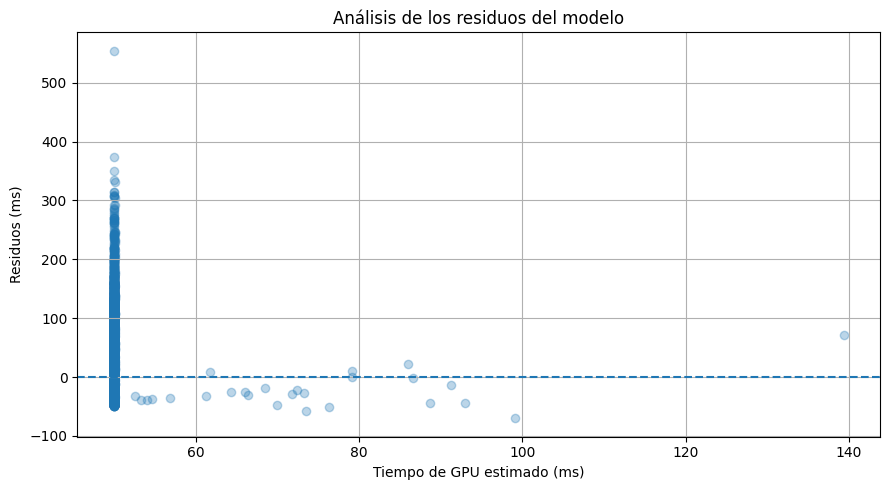

In [200]:
plt.figure(figsize=(9, 5))
# Representamos los residuos frente a los valores estimados
plt.scatter(y_estimado,residuos,alpha=0.3)
# Agregamos una línea horizontal en cero
plt.axhline(y=0,linestyle="--")

plt.title("Análisis de los residuos del modelo")
plt.xlabel("Tiempo de GPU estimado (ms)")
plt.ylabel("Residuos (ms)")
plt.grid()
plt.tight_layout()
plt.show()

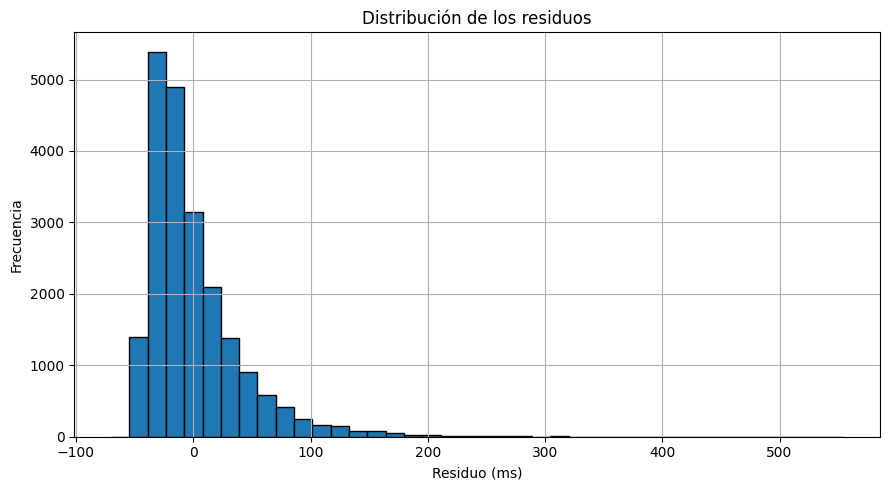

In [201]:
plt.figure(figsize=(9, 5))

plt.hist(residuos,bins=40,
    edgecolor="black"
)

plt.title("Distribución de los residuos")
plt.xlabel("Residuo (ms)")
plt.ylabel("Frecuencia")
plt.grid()
plt.tight_layout()
plt.show()

In [202]:
# Elevamos los residuos al cuadrado
residuos_cuadrados = residuos ** 2

# Resolvemos una regresión auxiliar de los residuos cuadrados
coef_auxiliar = np.linalg.solve(
    XtX,
    X.T @ residuos_cuadrados
)

# Calculamos los valores estimados de la regresión auxiliar
estimados_auxiliares = X @ coef_auxiliar

# Calculamos el R cuadrado de la regresión auxiliar
suma_auxiliar = np.sum(
    (residuos_cuadrados - estimados_auxiliares) ** 2
)

suma_total_auxiliar = np.sum(
    (residuos_cuadrados - np.mean(residuos_cuadrados)) ** 2
)

r2_auxiliar = 1 - (
    suma_auxiliar / suma_total_auxiliar
)

# Calculamos el estadístico de Breusch-Pagan
estadistico_bp = n * r2_auxiliar

# Calculamos el valor p
from scipy.stats import chi2

p_valor_bp = chi2.sf(
    estadistico_bp,
    df=1
)

print("PRUEBA DE BREUSCH-PAGAN")
print("Estadístico:", estadistico_bp)
print("Valor p:", p_valor_bp)

# Evaluamos el resultado
if p_valor_bp < alpha:
    print("\nSe encuentra evidencia de heterocedasticidad.")
else:
    print("\nNo se encuentra evidencia suficiente de heterocedasticidad.")

PRUEBA DE BREUSCH-PAGAN
Estadístico: 0.7531655659480165
Valor p: 0.38547584086982345

No se encuentra evidencia suficiente de heterocedasticidad.


In [203]:
# Inicialmente utilizamos los errores estándar clásicos
errores_finales = errores_estandar.copy()
# Revisamos si encontramos heterocedasticidad
if p_valor_bp < alpha:

    print("Aplicamos la corrección HC3.")

    # Calculamos los valores de influencia de cada observación
    influencia = np.sum(
        (X @ matriz_inversa) * X,
        axis=1
    )

    # Calculamos los residuos corregidos
    residuos_hc3 = residuos / (1 - influencia)
    # Calculamos los pesos de la corrección
    pesos_hc3 = residuos_hc3 ** 2

    # Construimos la matriz de varianzas robusta
    parte_central = X.T @ (
        X * pesos_hc3[:, np.newaxis]
    )

    matriz_hc3 = (
        matriz_inversa @ parte_central @ matriz_inversa
    )

    # Calculamos los nuevos errores estándar
    errores_finales = np.sqrt(
        np.diag(matriz_hc3)
    )

else:

    print("No se encontró evidencia suficiente de heterocedasticidad.")
    print("Conservamos los errores estándar clásicos.")

No se encontró evidencia suficiente de heterocedasticidad.
Conservamos los errores estándar clásicos.


In [204]:
# Calculamos los límites de los intervalos definitivos
limite_inferior_final = (
    beta - valor_critico * errores_finales
)

limite_superior_final = (
    beta + valor_critico * errores_finales
)

# Organizamos los resultados finales
resultados_finales = pd.DataFrame({
    "Coeficiente": ["Intercepto", "Pendiente"],
    "Estimacion": beta,
    "Error_estandar": errores_finales,
    "Limite_inferior": limite_inferior_final,
    "Limite_superior": limite_superior_final
})

print("RESULTADOS FINALES DEL MODELO")
print("Nivel de confianza:", confianza)
display(resultados_finales)

RESULTADOS FINALES DEL MODELO
Nivel de confianza: 0.99


,Coeficiente,Estimacion,Error_estandar,Limite_inferior,Limite_superior
0,Intercepto,49.941039,0.284955,49.206978,50.675101
1,Pendiente,0.000088,0.000023,0.000028,0.000147


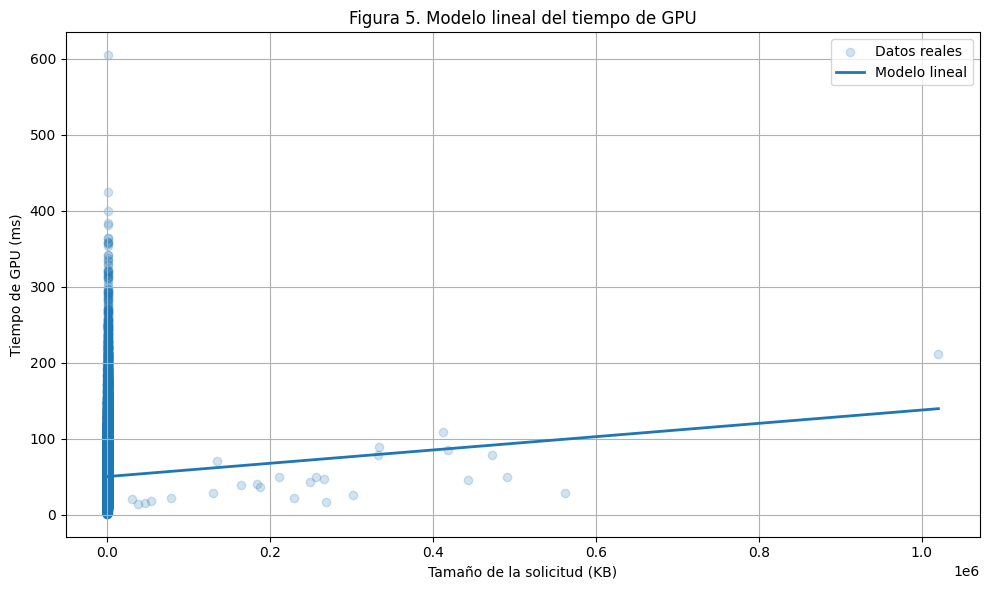

In [205]:
plt.figure(figsize=(10, 6))
# Representamos las solicitudes reales
plt.scatter(
    x,
    y,
    alpha=0.20,
    label="Datos reales"
)

# Ordenamos los tamaños para dibujar correctamente la recta
orden = np.argsort(x)
# Representamos la recta del modelo
plt.plot(
    x[orden],
    y_estimado[orden],
    linewidth=2,
    label="Modelo lineal"
)

plt.title("Figura 5. Modelo lineal del tiempo de GPU")
plt.xlabel("Tamaño de la solicitud (KB)")
plt.ylabel("Tiempo de GPU (ms)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

**D4.** Calcule la covarianza y la correlación entre tam_kb y gpu_ms (no cacheadas) e interprete su relación con los resultados de D2 y D3.


In [206]:
# Creamos una copia de los datos
datos_d4 = datos_d2.copy()

# Seleccionamos las solicitudes que no utilizaron caché
datos_d4 = datos_d4[
    datos_d4["cache_hit"] == 0
].copy()

# Eliminamos los registros que tengan valores faltantes
datos_d4 = datos_d4.dropna(
    subset=["tam_kb", "gpu_ms"]
)

# Mostramos la cantidad de datos disponibles
print("Solicitudes sin caché:", len(datos_d4))
# Revisamos las primeras filas
display(datos_d4[["tam_kb", "gpu_ms"]].head())

Solicitudes sin caché: 21088


,tam_kb,gpu_ms
0,108.47,8.37
1,629.91,149.39
2,179.72,49.68
3,429.34,66.91
4,229.65,33.09


In [207]:
# Obtenemos los valores de las dos variables
tamano = datos_d4["tam_kb"].to_numpy()
tiempo_gpu = datos_d4["gpu_ms"].to_numpy()

# Calculamos la covarianza
covarianza = np.cov(
    tamano,
    tiempo_gpu,
    ddof=1
)[0, 1]

# Mostramos el resultado
print("Covarianza entre tam_kb y gpu_ms:")
print(covarianza)

Covarianza entre tam_kb y gpu_ms:
13213.0716551912


In [208]:
# Calculamos la correlación entre las dos variables
correlacion = np.corrcoef(
    tamano,
    tiempo_gpu
)[0, 1]

# Mostramos el resultado
print("Correlación entre tam_kb y gpu_ms:")
print(correlacion)

Correlación entre tam_kb y gpu_ms:
0.026017667267918997


In [209]:
# Organizamos los resultados en una tabla
resultados_d4 = pd.DataFrame({
    "Medida": ["Covarianza", "Correlacion"],
    "Resultado": [covarianza, correlacion]
})

# Mostramos la tabla
print("Resultados de D4:")
display(resultados_d4)

Resultados de D4:


,Medida,Resultado
0,Covarianza,13213.071655
1,Correlacion,0.026018


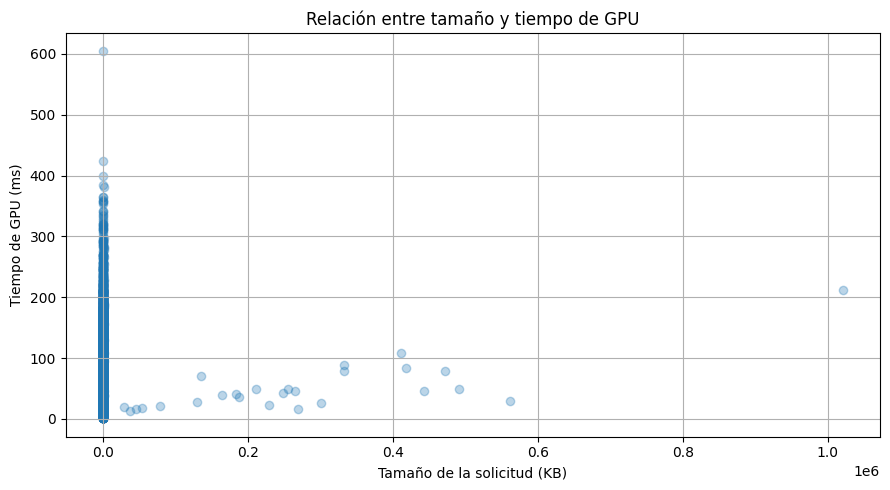

In [210]:
plt.figure(figsize=(9, 5))

plt.scatter(
    tamano,
    tiempo_gpu,
    alpha=0.3
)

plt.title("Relación entre tamaño y tiempo de GPU")
plt.xlabel("Tamaño de la solicitud (KB)")
plt.ylabel("Tiempo de GPU (ms)")
plt.grid()
plt.tight_layout()
plt.show()

# Parte E — Monitoreo y decisión de alertas

**E1.** Estime con intervalos de confianza la sensibilidad y la tasa de falsos positivos de D1,
de D2 y de las reglas combinadas “D1 y D2” y “D1 o D2”.

In [211]:
monitoreo = pd.read_csv("monitoreo.csv")
# Copiamos los datos de monitoreo para trabajar sobre ellos
datos_e1 = monitoreo.copy()
# Revisamos las primeras filas
display(datos_e1.head())

# Revisamos si hay datos faltantes
print("Datos faltantes:")
print(datos_e1[["D1", "D2", "incidente"]].isnull().sum())

# Revisamos los valores que aparecen en cada columna
print("\nValores de D1:")
print(datos_e1["D1"].value_counts(dropna=False))
print("\nValores de D2:")
print(datos_e1["D2"].value_counts(dropna=False))
print("\nValores de incidente:")
print(datos_e1["incidente"].value_counts(dropna=False))

,minuto,D1,D2,incidente
0,1,0,0,0
1,2,0,0,0
2,3,1,1,1
3,4,0,0,0
4,5,0,0,0


Datos faltantes:
D1           0
D2           0
incidente    0
dtype: int64

Valores de D1:
D1
0    5351
1     649
Name: count, dtype: int64

Valores de D2:
D2
0    5435
1     565
Name: count, dtype: int64

Valores de incidente:
incidente
0    5310
1     690
Name: count, dtype: int64


In [212]:
# Eliminamos filas que no tengan información en las variables necesarias
datos_e1 = datos_e1.dropna(subset=["D1", "D2", "incidente"]).copy()

# Convertimos las columnas a enteros
datos_e1["D1"] = datos_e1["D1"].astype(int)
datos_e1["D2"] = datos_e1["D2"].astype(int)
datos_e1["incidente"] = datos_e1["incidente"].astype(int)

# Creamos las dos reglas combinadas
datos_e1["D1_y_D2"] = (
    (datos_e1["D1"] == 1) & (datos_e1["D2"] == 1)
).astype(int)

datos_e1["D1_o_D2"] = (
    (datos_e1["D1"] == 1) | (datos_e1["D2"] == 1)
).astype(int)

# Revisamos cuántos minutos quedaron y los incidentes
print("Cantidad de minutos utilizados:", len(datos_e1))
print("\nEstado real del sistema:")
print(datos_e1["incidente"].value_counts().sort_index())

Cantidad de minutos utilizados: 6000

Estado real del sistema:
incidente
0    5310
1     690
Name: count, dtype: int64


In [213]:
S = 4063981172

# Calculamos el nivel de confianza correspondiente
if S % 3 == 0:
    confianza = 0.90
elif S % 3 == 1:
    confianza = 0.95
else:
    confianza = 0.99

alpha = 1 - confianza

print("Residuo de S al dividir entre 3:", S % 3)
print("Nivel de confianza:", confianza * 100, "%")

Residuo de S al dividir entre 3: 2
Nivel de confianza: 99.0 %


In [214]:
import numpy as np
import pandas as pd
from scipy.stats import norm

def intervalo_wilson(exitos, total, confianza):

    # Calculamos la proporción observada
    p = exitos / total
    # Valor crítico según el nivel de confianza
    z = norm.ppf(1 - (1 - confianza) / 2)
    # Parte inferior y superior del intervalo
    denominador = 1 + (z**2 / total)
    centro = (p + z**2 / (2 * total)) / denominador

    margen = (
        z * np.sqrt(
            (p * (1 - p) / total) +
            (z**2 / (4 * total**2))
        ) / denominador
    )

    limite_inferior = centro - margen
    limite_superior = centro + margen

    return limite_inferior, limite_superior

In [215]:
# Separamos los minutos con incidentes y sin incidentes
con_incidente = datos_e1[datos_e1["incidente"] == 1]
sin_incidente = datos_e1[datos_e1["incidente"] == 0]

# Reglas que vamos a evaluar
reglas = ["D1", "D2", "D1_y_D2", "D1_o_D2"]

# Guardamos los resultados
resultados_e1 = []

for regla in reglas:

    # Verdaderos positivos: alerta cuando sí había incidente
    verdaderos_positivos = con_incidente[regla].sum()

    # Falsos positivos: alerta cuando no había incidente
    falsos_positivos = sin_incidente[regla].sum()

    # Calculamos la sensibilidad
    total_incidentes = len(con_incidente)

    sensibilidad = verdaderos_positivos / total_incidentes

    ic_sensibilidad = intervalo_wilson(
        verdaderos_positivos,
        total_incidentes,
        confianza
    )

    # Calculamos la tasa de falsos positivos
    total_sin_incidente = len(sin_incidente)

    tasa_falsos_positivos = falsos_positivos / total_sin_incidente

    ic_falsos_positivos = intervalo_wilson(
        falsos_positivos,
        total_sin_incidente,
        confianza
    )

    # Guardamos los resultados de cada regla
    resultados_e1.append({
        "Regla": regla,
        "Sensibilidad": sensibilidad,
        "Sensibilidad inferior": ic_sensibilidad[0],
        "Sensibilidad superior": ic_sensibilidad[1],
        "Tasa falsos positivos": tasa_falsos_positivos,
        "Falsos positivos inferior": ic_falsos_positivos[0],
        "Falsos positivos superior": ic_falsos_positivos[1]
    })

# Convertimos los resultados en una tabla
tabla_e1 = pd.DataFrame(resultados_e1)

display(tabla_e1)

,Regla,Sensibilidad,Sensibilidad inferior,Sensibilidad superior,Tasa falsos positivos,Falsos positivos inferior,Falsos positivos superior
0,D1,0.873913,0.837761,0.902942,0.008663,0.005945,0.012607
1,D2,0.760870,0.716683,0.800087,0.007533,0.005032,0.011263
2,D1_y_D2,0.662319,0.614594,0.706952,0.001507,0.000624,0.003633
3,D1_o_D2,0.972464,0.951372,0.984556,0.014689,0.011002,0.019588


In [216]:
# Creamos una copia para mostrar los resultados en porcentajes
tabla_e1_porcentajes = tabla_e1.copy()

columnas_porcentaje = [
    "Sensibilidad",
    "Sensibilidad inferior",
    "Sensibilidad superior",
    "Tasa falsos positivos",
    "Falsos positivos inferior",
    "Falsos positivos superior"
]

for columna in columnas_porcentaje:
    tabla_e1_porcentajes[columna] = (
        tabla_e1_porcentajes[columna] * 100
    ).round(2)

display(tabla_e1_porcentajes)

,Regla,Sensibilidad,Sensibilidad inferior,Sensibilidad superior,Tasa falsos positivos,Falsos positivos inferior,Falsos positivos superior
0,D1,87.39,83.78,90.29,0.87,0.59,1.26
1,D2,76.09,71.67,80.01,0.75,0.50,1.13
2,D1_y_D2,66.23,61.46,70.70,0.15,0.06,0.36
3,D1_o_D2,97.25,95.14,98.46,1.47,1.10,1.96


**E2.** Calcule, para producción (con la prevalencia π de su grupo), la probabilidad de que
haya un incidente real dado cada una de las cuatro reglas de alerta. Explique por qué estas cifras
difieren de las que se obtendrían directamente de monitoreo.csv.

In [217]:
S = 4063981172

# Calculamos la prevalencia de incidentes en producción
pi = (4 + (S % 6)) / 1000

print("Residuo de S al dividir entre 6:", S % 6)
print("Prevalencia de producción:", pi)
print("Prevalencia en porcentaje:", round(pi * 100, 2), "%")

Residuo de S al dividir entre 6: 2
Prevalencia de producción: 0.006
Prevalencia en porcentaje: 0.6 %


In [218]:
# Creamos una lista para guardar los resultados
resultados_e2 = []

for i, fila in tabla_e1.iterrows():

    # Tomamos la sensibilidad y la tasa de falsos positivos de E1
    sensibilidad = fila["Sensibilidad"]
    tasa_falsos_positivos = fila["Tasa falsos positivos"]

    # Aplicamos la fórmula de Bayes
    numerador = sensibilidad * pi

    denominador = (
        sensibilidad * pi +
        tasa_falsos_positivos * (1 - pi)
    )

    # Calculamos la probabilidad de incidente dado que hubo alerta
    if denominador > 0:
        probabilidad_incidente = numerador / denominador
    else:
        probabilidad_incidente = np.nan

    # Guardamos el resultado
    resultados_e2.append({
        "Regla": fila["Regla"],
        "Probabilidad de incidente": probabilidad_incidente
    })

# Creamos la tabla final
tabla_e2 = pd.DataFrame(resultados_e2)

display(tabla_e2)

,Regla,Probabilidad de incidente
0,D1,0.378470
1,D2,0.378763
2,D1_y_D2,0.726298
3,D1_o_D2,0.285516


In [219]:
tabla_e2_porcentajes = tabla_e2.copy()

tabla_e2_porcentajes["Probabilidad de incidente"] = (
    tabla_e2_porcentajes["Probabilidad de incidente"] * 100
).round(2)

display(tabla_e2_porcentajes)

,Regla,Probabilidad de incidente
0,D1,37.85
1,D2,37.88
2,D1_y_D2,72.63
3,D1_o_D2,28.55


**E3.** Verifique con datos, y no por suposición, si D1 y D2 son condicionalmente independientes dado el estado del sistema. Cuantifique el efecto de su conclusión sobre la probabilidad calculada en E2.

In [220]:
import pandas as pd
from scipy.stats import chi2_contingency

# Cargar los datos
datos_e3 = pd.read_csv("monitoreo.csv")

# Nivel de significancia del grupo
confianza = 0.99
alpha = 1 - confianza

# Separar los datos según el estado real del sistema
for estado in [0, 1]:

    grupo = datos_e3[datos_e3["incidente"] == estado]

    # Crear tabla de frecuencias entre D1 y D2
    tabla = pd.crosstab(grupo["D1"], grupo["D2"])

    # Prueba chi-cuadrado de independencia
    chi2, p_valor, grados, esperados = chi2_contingency(
        tabla, correction=False
    )

    print("\nEstado del sistema:", estado)
    print("Cantidad de observaciones:", len(grupo))
    print("Tabla de frecuencias:")
    display(tabla)

    print("Chi-cuadrado:", chi2)
    print("Valor p:", p_valor)

    if p_valor < alpha:
        print("Conclusión: se rechaza la independencia.")
    else:
        print("Conclusión: no hay evidencia suficiente para rechazar la independencia.")



Estado del sistema: 0
Cantidad de observaciones: 5310
Tabla de frecuencias:


D2,0,1
D1,,
0,5232,32
1,38,8


Chi-cuadrado: 171.81362497551913
Valor p: 2.9721087640080735e-39
Conclusión: se rechaza la independencia.

Estado del sistema: 1
Cantidad de observaciones: 690
Tabla de frecuencias:


D2,0,1
D1,,
0,19,68
1,146,457


Chi-cuadrado: 0.23534662855301047
Valor p: 0.6275874139205906
Conclusión: no hay evidencia suficiente para rechazar la independencia.


In [221]:
import numpy as np
import pandas as pd

S = 4063981172
pi = (4 + (S % 6)) / 1000

# Separar los datos según el estado del sistema
sin_incidente = datos_e3[datos_e3["incidente"] == 0]
con_incidente = datos_e3[datos_e3["incidente"] == 1]

# Probabilidades individuales observadas
p_d1_sin = sin_incidente["D1"].mean()
p_d2_sin = sin_incidente["D2"].mean()

p_d1_con = con_incidente["D1"].mean()
p_d2_con = con_incidente["D2"].mean()

# Probabilidades conjuntas observadas
p_and_sin = (
    (sin_incidente["D1"] == 1) &
    (sin_incidente["D2"] == 1)
).mean()

p_and_con = (
    (con_incidente["D1"] == 1) &
    (con_incidente["D2"] == 1)
).mean()

# Regla OR: probabilidad de que al menos una alerta se active
p_or_sin = (
    (sin_incidente["D1"] == 1) |
    (sin_incidente["D2"] == 1)
).mean()

p_or_con = (
    (con_incidente["D1"] == 1) |
    (con_incidente["D2"] == 1)
).mean()

# Calcular probabilidad de incidente real
def calcular_posterior(sensibilidad, falsos_positivos):
    numerador = sensibilidad * pi
    denominador = numerador + falsos_positivos * (1 - pi)

    return numerador / denominador

# Resultados usando las frecuencias conjuntas observadas
observados = {
    "D1": calcular_posterior(p_d1_con, p_d1_sin),
    "D2": calcular_posterior(p_d2_con, p_d2_sin),
    "D1 y D2": calcular_posterior(p_and_con, p_and_sin),
    "D1 o D2": calcular_posterior(p_or_con, p_or_sin)
}

# Resultados suponiendo independencia condicional
p_and_sin_ind = p_d1_sin * p_d2_sin
p_and_con_ind = p_d1_con * p_d2_con

p_or_sin_ind = p_d1_sin + p_d2_sin - p_and_sin_ind
p_or_con_ind = p_d1_con + p_d2_con - p_and_con_ind

independencia = {
    "D1": calcular_posterior(p_d1_con, p_d1_sin),
    "D2": calcular_posterior(p_d2_con, p_d2_sin),
    "D1 y D2": calcular_posterior(p_and_con_ind, p_and_sin_ind),
    "D1 o D2": calcular_posterior(p_or_con_ind, p_or_sin_ind)
}

# Comparar los resultados
comparacion = pd.DataFrame({
    "Regla": observados.keys(),
    "Con datos observados": observados.values(),
    "Suponiendo independencia": independencia.values()
})

comparacion["Diferencia en puntos porcentuales"] = (
    comparacion["Con datos observados"] -
    comparacion["Suponiendo independencia"]
) * 100

comparacion["Con datos observados"] *= 100
comparacion["Suponiendo independencia"] *= 100

display(comparacion.round(2))


,Regla,Con datos observados,Suponiendo independencia,Diferencia en puntos porcentuales
0,D1,37.85,37.85,0.00
1,D2,37.88,37.88,0.00
2,D1 y D2,72.63,98.40,-25.77
3,D1 o D2,28.55,26.63,1.92


**E4.** El equipo de guardia exige que, con probabilidad al menos 0,90, el número de falsas
alarmas en un día (1440 minutos) no supere km´ax. Determine qué reglas cumplen la exigencia,
propague la incertidumbre de la estimación hasta su conclusión y recomiende una regla. Figura 6.


In [222]:
import pandas as pd
import numpy as np
from scipy.stats import beta, betabinom, norm
import matplotlib.pyplot as plt

# Cargar los datos
datos_e4 = pd.read_csv("monitoreo.csv")

# Definir las reglas combinadas
datos_e4["D1_y_D2"] = (
    (datos_e4["D1"] == 1) & (datos_e4["D2"] == 1)
).astype(int)

datos_e4["D1_o_D2"] = (
    (datos_e4["D1"] == 1) | (datos_e4["D2"] == 1)
).astype(int)

# Conservar solamente los minutos sin incidentes
sin_incidente = datos_e4[datos_e4["incidente"] == 0].copy()

# Parámetros del grupo
S = 4063981172
confianza = 0.99
alpha = 1 - confianza
k_max = 4 + (S % 5)

print("Minutos sin incidentes:", len(sin_incidente))
print("Máximo de falsas alarmas permitido:", k_max)

# Reglas que vamos a evaluar
reglas = ["D1", "D2", "D1_y_D2", "D1_o_D2"]

resultados = []

for regla in reglas:

    # Número de falsas alarmas observadas
    x = int(sin_incidente[regla].sum())
    n = len(sin_incidente)

    # Tasa estimada de falsas alarmas
    tasa = x / n

    # Límite superior del intervalo Wilson del 99 %
    z = norm.ppf(1 - alpha / 2)
    denominador = 1 + z**2 / n

    centro = (tasa + z**2 / (2 * n)) / denominador

    margen = (
        z * np.sqrt(
            tasa * (1 - tasa) / n +
            z**2 / (4 * n**2)
        ) / denominador
    )

    limite_inferior = centro - margen
    limite_superior = centro + margen

    # Distribución predictiva Beta-Binomial
    # Se usa el prior de Jeffreys Beta(0.5, 0.5)
    a = x + 0.5
    b = n - x + 0.5

    probabilidad_cumplir = betabinom.cdf(
        k_max, 1440, a, b
    )

    # Comprobación conservadora usando el límite superior
    probabilidad_limite = betabinom.cdf(
        k_max, 1440, n * limite_superior + 0.5,
        n * (1 - limite_superior) + 0.5
    )

    resultados.append({
        "Regla": regla,
        "Falsas alarmas observadas": x,
        "Tasa estimada": tasa,
        "Límite inferior 99%": limite_inferior,
        "Límite superior 99%": limite_superior,
        "P(N <= 6)": probabilidad_cumplir,
        "P(N <= 6) límite superior": probabilidad_limite
    })

tabla_e4 = pd.DataFrame(resultados)

display(tabla_e4.round(5))


Minutos sin incidentes: 5310
Máximo de falsas alarmas permitido: 6


,Regla,Falsas alarmas observadas,Tasa estimada,Límite inferior 99%,Límite superior 99%,P(N <= 6),P(N <= 6) límite superior
0,D1,46,0.00866,0.00595,0.01261,0.04906,0.00214
1,D2,40,0.00753,0.00503,0.01126,0.10540,0.00665
2,D1_y_D2,8,0.00151,0.00062,0.00363,0.97946,0.69664
3,D1_o_D2,78,0.01469,0.01100,0.01959,0.00033,0.00000


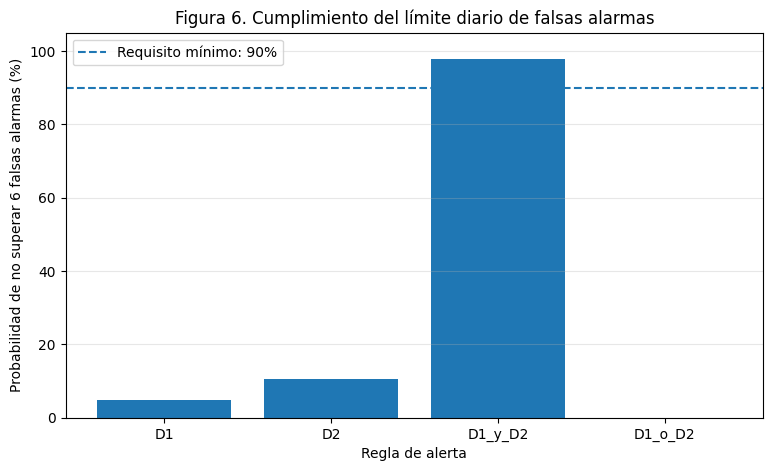

In [223]:
plt.figure(figsize=(9, 5))

plt.bar(
    tabla_e4["Regla"],
    tabla_e4["P(N <= 6)"] * 100
)

plt.axhline(
    y=90,
    linestyle="--",
    label="Requisito mínimo: 90%"
)

plt.ylabel("Probabilidad de no superar 6 falsas alarmas (%)")
plt.xlabel("Regla de alerta")
plt.title("Figura 6. Cumplimiento del límite diario de falsas alarmas")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()